# Pothole + Crack Detection: Complete Colab Pipeline (YOLOv8s)
Download, remap, train and evaluate, all in one notebook. Local files are not needed.

**Before you start**
1. Runtime → Change runtime type → **T4 GPU**
2. Paste your Roboflow API key in Cell 2 (roboflow.com → Settings → API Key)
3. Run all cells from top to bottom

If Colab disconnects during training, go to the **Resume** cell. Do not re-run the train cell.

## 1. Setup

In [1]:
!nvidia-smi
!pip install -q ultralytics roboflow

Sun Nov 22 09:00:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Config (paste your API key here)

In [4]:
ROBOFLOW_API_KEY = "kB7quvjM03DuV0C0pQOZ"   # <-- PASTE YOUR KEY HERE

# (workspace, project, version). Add more datasets as extra lines.
# For each dataset, open its page on universe.roboflow.com, click Download, pick YOLOv8, and copy the workspace/project/version.
DATASETS = [
    ("demo-tracking", "indiardd2022", 1),
    # ("WORKSPACE", "PROJECT", 1),   # optional: extra pothole dataset
]

# Training settings
EPOCHS   = 100
PATIENCE = 20
IMGSZ    = 960
BATCH    = 16      # on an out-of-memory error, change to 8

DRIVE_DIR = '/content/drive/MyDrive/pothole'
assert ROBOFLOW_API_KEY or True

## 3. Mount Drive

In [5]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs(f'{DRIVE_DIR}/runs', exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 4. Get the dataset
If `processed.zip` already exists in Drive (from an earlier run), it is reused and the download is skipped.

In [6]:
import os, shutil, glob, yaml

OUT = '/content/processed'
ZIP_ON_DRIVE = f'{DRIVE_DIR}/processed.zip'

if os.path.exists(ZIP_ON_DRIVE):
    print('Found processed.zip in Drive, using it (skipping download).')
    !cp {ZIP_ON_DRIVE} /content/processed.zip
    !unzip -q -o /content/processed.zip -d /content/
else:
    assert ROBOFLOW_API_KEY, 'Paste your Roboflow API key in the Config cell first!'
    from roboflow import Roboflow
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    for ws, proj, ver in DATASETS:
        print(f'Downloading {ws}/{proj} v{ver} ...')
        rf.workspace(ws).project(proj).version(ver).download('yolov8', location=f'/content/raw/{proj}')

    # Class names of every downloaded dataset
    for f in glob.glob('/content/raw/*/data.yaml'):
        print(f, '->', yaml.safe_load(open(f))['names'])

    # Remap to 2 classes: 0 = pothole, 1 = crack
    for s in ['train', 'val', 'test']:
        os.makedirs(f'{OUT}/{s}/images', exist_ok=True)
        os.makedirs(f'{OUT}/{s}/labels', exist_ok=True)

    def to_new(name):
        n = str(name).lower()
        if any(k in n for k in ['pothole', 'd40', 'd44']): return 0
        if any(k in n for k in ['crack', 'd00', 'd10', 'd20', 'alligator', 'longitud', 'transv']): return 1
        return None   # other classes are dropped

    split_map = {'train': 'train', 'valid': 'val', 'val': 'val', 'test': 'test'}
    for ds in glob.glob('/content/raw/*'):
        names = yaml.safe_load(open(f'{ds}/data.yaml'))['names']
        if isinstance(names, list): names = dict(enumerate(names))
        remap = {int(k): to_new(v) for k, v in names.items()}
        tag = os.path.basename(ds)
        print(tag, 'remap:', remap)
        for src, dst in split_map.items():
            for img in glob.glob(f'{ds}/{src}/images/*'):
                base = os.path.splitext(os.path.basename(img))[0]
                lbl = f'{ds}/{src}/labels/{base}.txt'
                if not os.path.exists(lbl): continue
                lines = []
                for line in open(lbl):
                    p = line.split()
                    if not p: continue
                    new = remap.get(int(float(p[0])))
                    if new is not None:
                        lines.append(' '.join([str(new)] + p[1:]))
                if not lines: continue
                shutil.copy(img, f'{OUT}/{dst}/images/{tag}_{os.path.basename(img)}')
                open(f'{OUT}/{dst}/labels/{tag}_{base}.txt', 'w').write('\n'.join(lines))

    # Save to Drive so the download is not repeated next time
    !cd /content && zip -rq processed.zip processed
    !cp /content/processed.zip {ZIP_ON_DRIVE}
    print('Saved processed.zip to Drive.')

Found processed.zip in Drive, using it (skipping download).


## 5. dataset.yaml and class distribution check

In [7]:
import collections
root = '/content/processed'
cfg = {'path': root, 'train': 'train/images', 'val': 'val/images',
       'names': {0: 'pothole', 1: 'crack'}}
if glob.glob(f'{root}/test/images/*'):
    cfg['test'] = 'test/images'
yaml.safe_dump(cfg, open('/content/dataset.yaml', 'w'))

totals = collections.Counter()
for split in ['train', 'val', 'test']:
    cnt = collections.Counter()
    files = glob.glob(f'{root}/{split}/labels/*.txt')
    for f in files:
        for line in open(f):
            if line.strip(): cnt[int(line.split()[0])] += 1
    totals.update(cnt if split == 'train' else {})
    print(f"{split:5s}: {len(files):5d} images | pothole={cnt[0]:6d}  crack={cnt[1]:6d}")

ratio = totals[1] / max(totals[0], 1)
print(f"\ncrack / pothole ratio (train) = {ratio:.2f}")
if ratio < 0.15:
    print("WARNING: crack is very low (<15%). Crack mAP may come out near 0. Check the class names and remap above before training.")

train:  5033 images | pothole= 14552  crack=  8005
val  :   338 images | pothole=   846  crack=   193
test :   340 images | pothole=   959  crack=   214

crack / pothole ratio (train) = 0.55


## 6. Train

In [8]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')
model.train(
    data='/content/dataset.yaml',
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMGSZ,
    batch=BATCH,
    workers=2,
    project=f'{DRIVE_DIR}/runs',   # saved to Drive, so it survives a disconnect
    name='full',
    exist_ok=True,
    save_period=5,
    mosaic=1.0, fliplr=0.5, hsv_v=0.4, scale=0.5,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=No

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a32d68e3230>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

### Resume (use ONLY if Colab disconnected mid-training)
Run cells 1, 2 and 3, then this cell.

In [9]:
from ultralytics import YOLO
model = YOLO(f'{DRIVE_DIR}/runs/full/weights/last.pt')
model.train(resume=True)

WARNING ⚠️ model '/content/drive/MyDrive/pothole/runs/full/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, li

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0, 16, 17, 20, 25, 58])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a32d00f30e0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

## 7. Evaluate (overall and per-class)

In [10]:
from ultralytics import YOLO
best = f'{DRIVE_DIR}/runs/full/weights/best.pt'
model = YOLO(best)
split = 'test' if 'test' in cfg else 'val'
m = model.val(data='/content/dataset.yaml', split=split, imgsz=IMGSZ, plots=True)

print(f"\nOverall: mAP50={m.box.map50:.3f}  mAP50-95={m.box.map:.3f}  P={m.box.mp:.3f}  R={m.box.mr:.3f}")
for i, name in model.names.items():
    p, r, ap50, ap = m.box.class_result(i)
    print(f"{name:8s} P={p:.3f} R={r:.3f} mAP50={ap50:.3f} mAP50-95={ap:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 23.2±23.9 MB/s, size: 61.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/processed/test/labels... 340 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 340/340 497.3it/s 0.7s
val: New cache created: /content/processed/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 1.8it/s 12.0s
                   all        340       1173      0.567      0.477      0.473      0.261
               pothole        337        959      0.739      0.743      0.758      0.461
                 crack         77        214      0.396       0.21      0.187     0.0615
Speed: 3.4ms pr

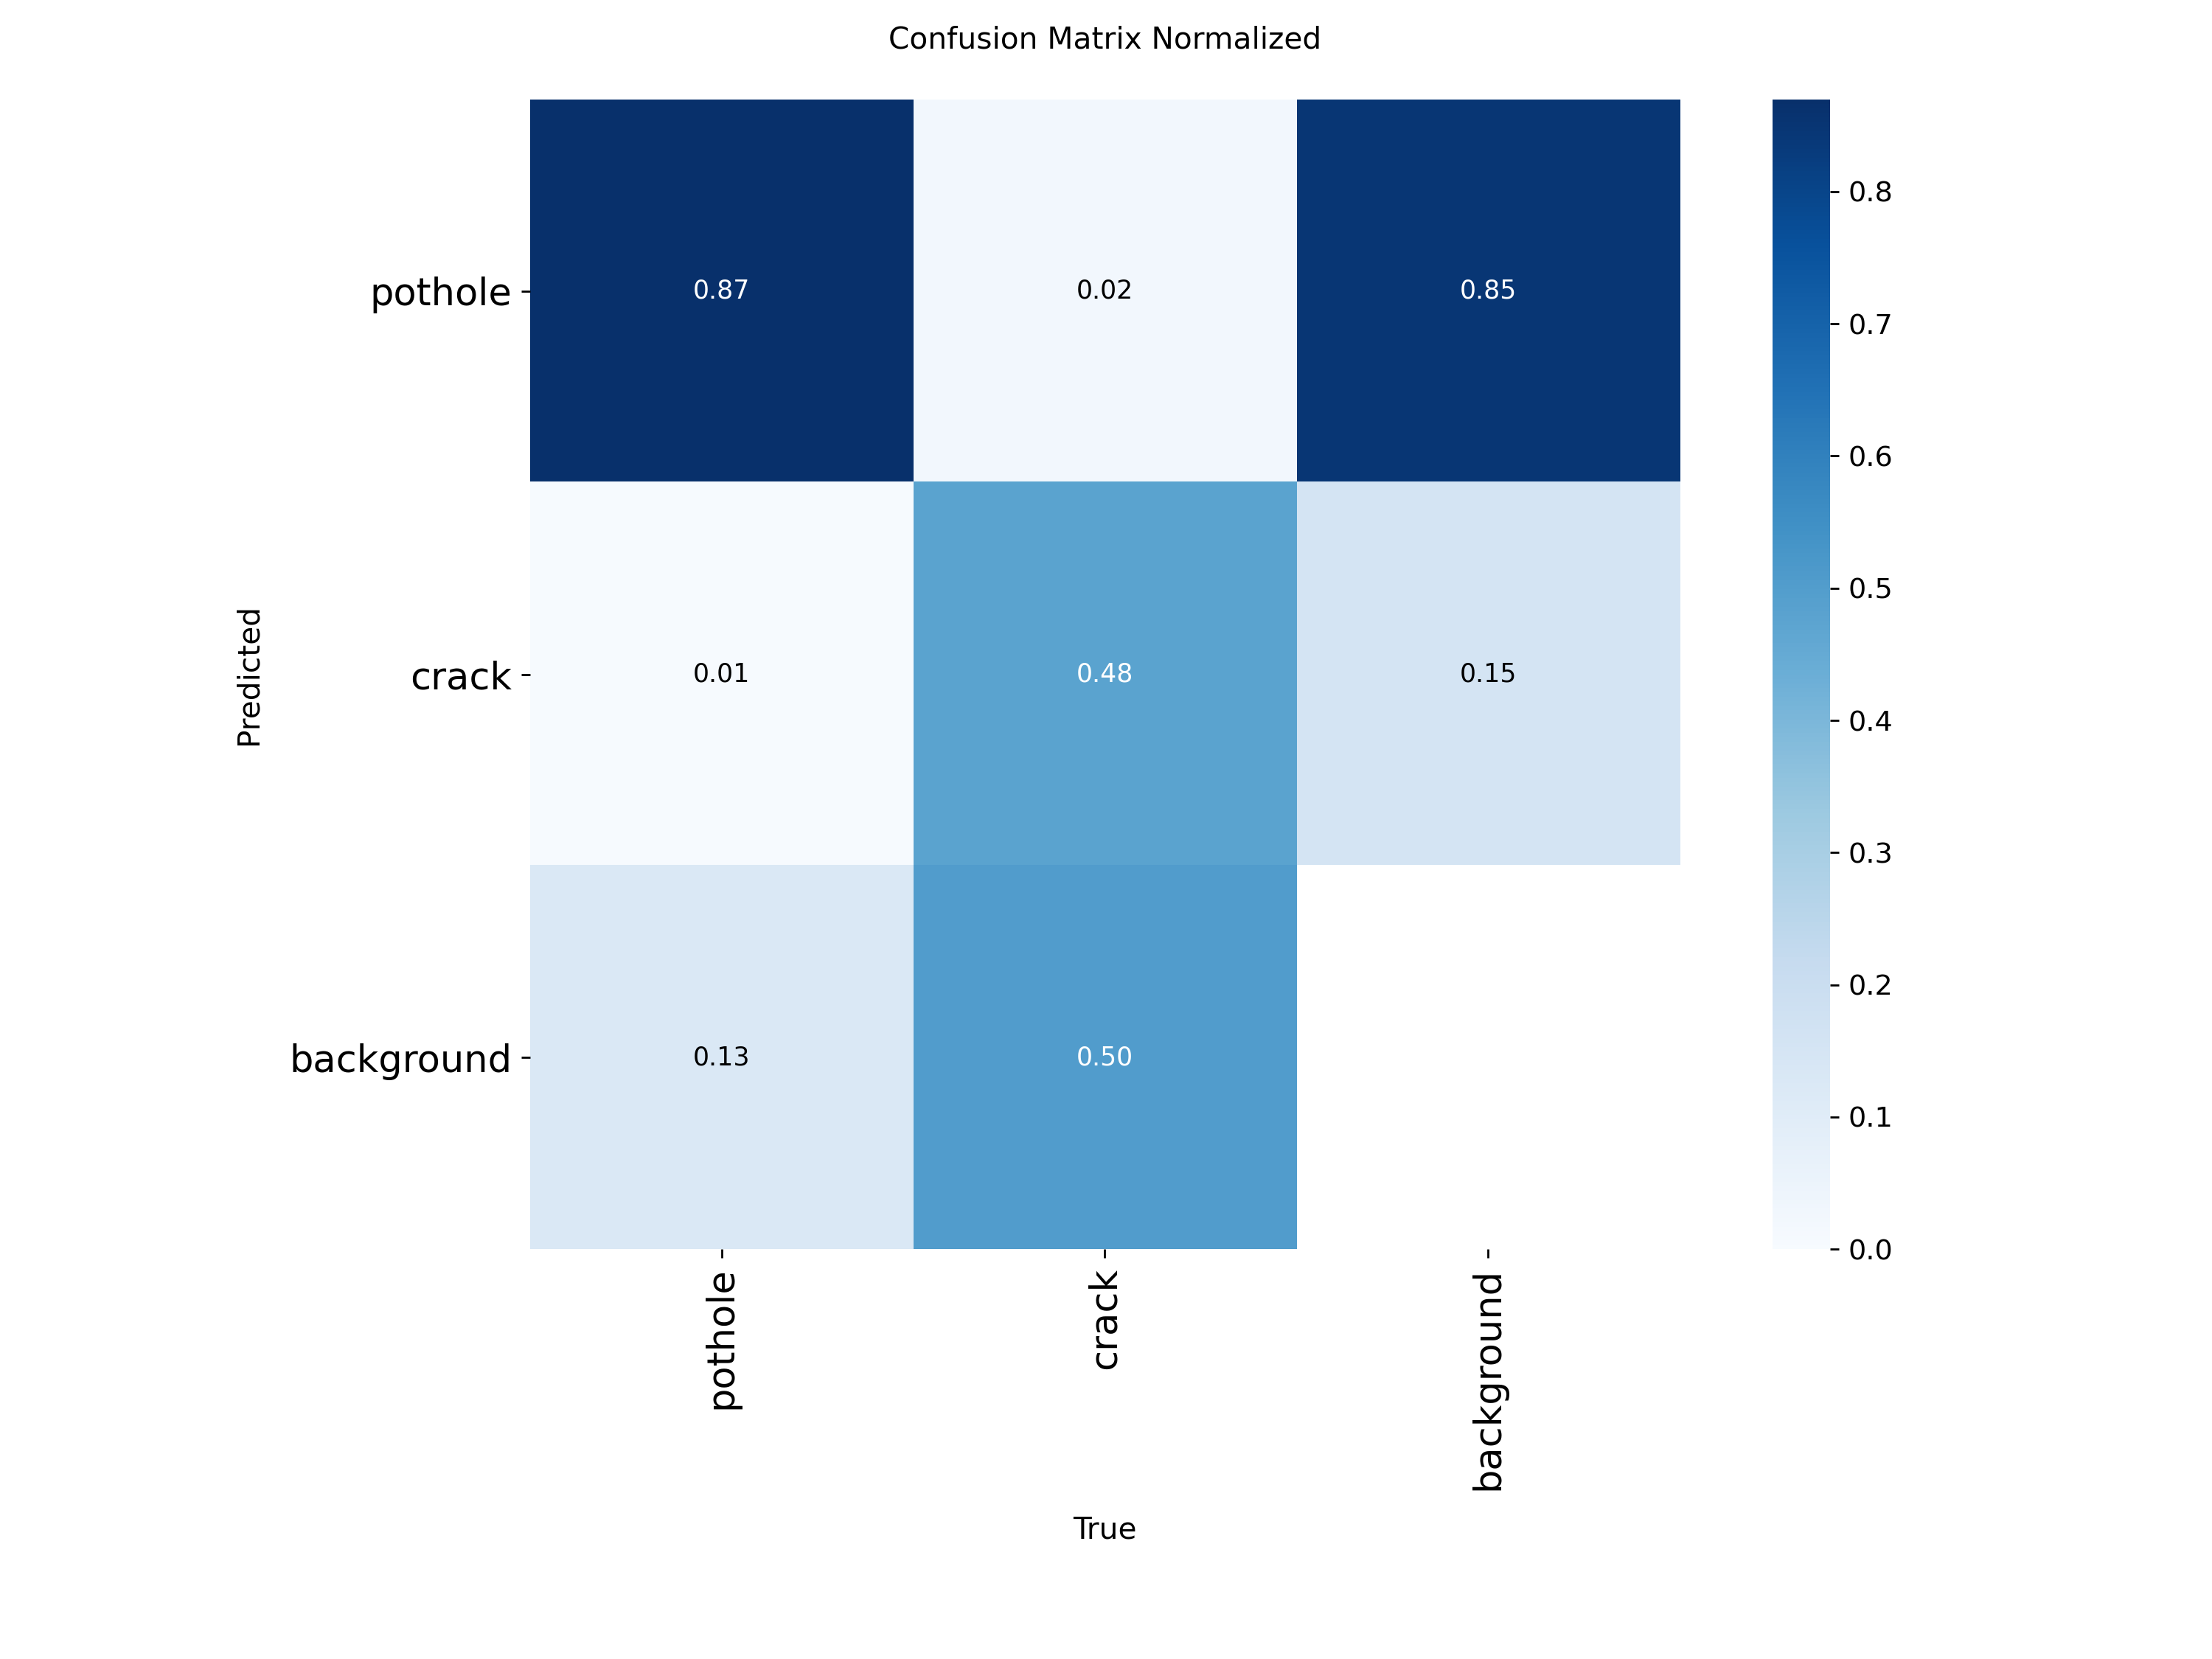

FileNotFoundError: No such file or directory: '/content/runs/detect/val/PR_curve.png'

FileNotFoundError: No such file or directory: '/content/runs/detect/val/PR_curve.png'

<IPython.core.display.Image object>

In [12]:
from IPython.display import Image, display
for f in ['confusion_matrix_normalized.png', 'PR_curve.png']:
    display(Image(f'{m.save_dir}/{f}'))


0: 960x960 1 pothole, 26.9ms
1: 960x960 2 potholes, 3 cracks, 26.9ms
2: 960x960 2 potholes, 26.9ms
3: 960x960 1 pothole, 26.9ms
4: 960x960 3 potholes, 26.9ms
5: 960x960 1 pothole, 26.9ms
Speed: 3.8ms preprocess, 26.9ms inference, 1.7ms postprocess per image at shape (1, 3, 960, 960)
Results saved to /content/preds/check


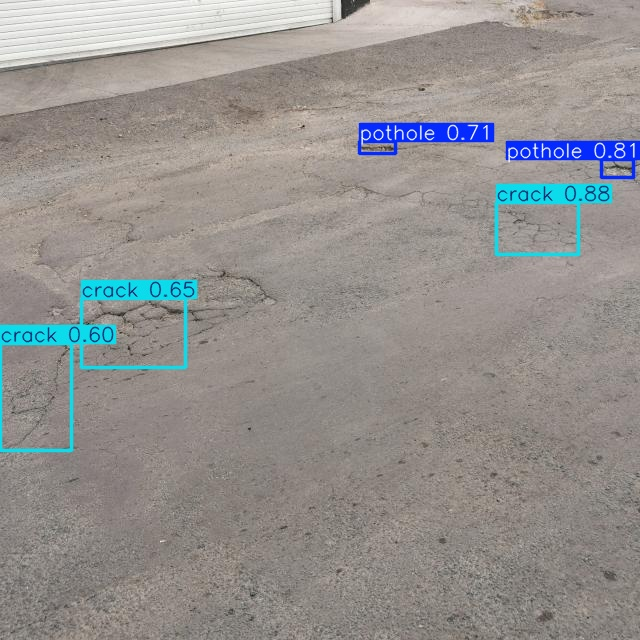

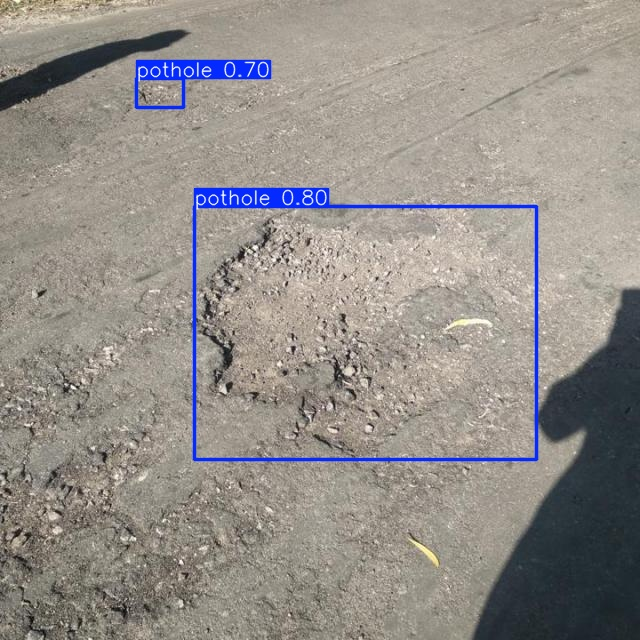

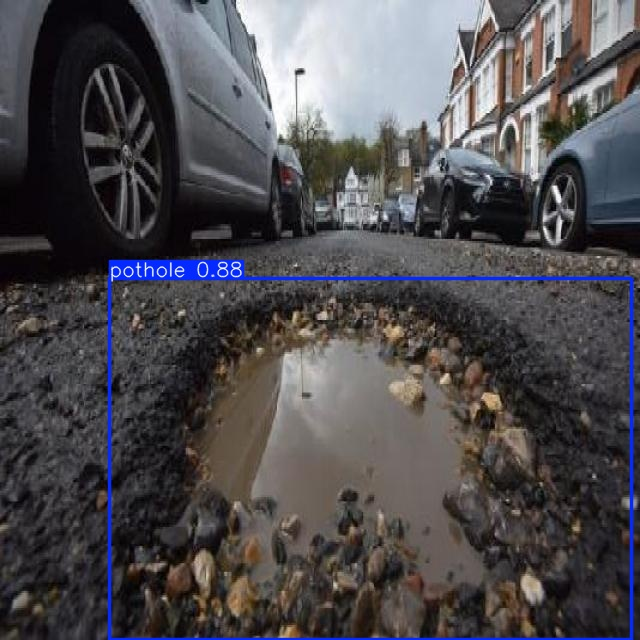

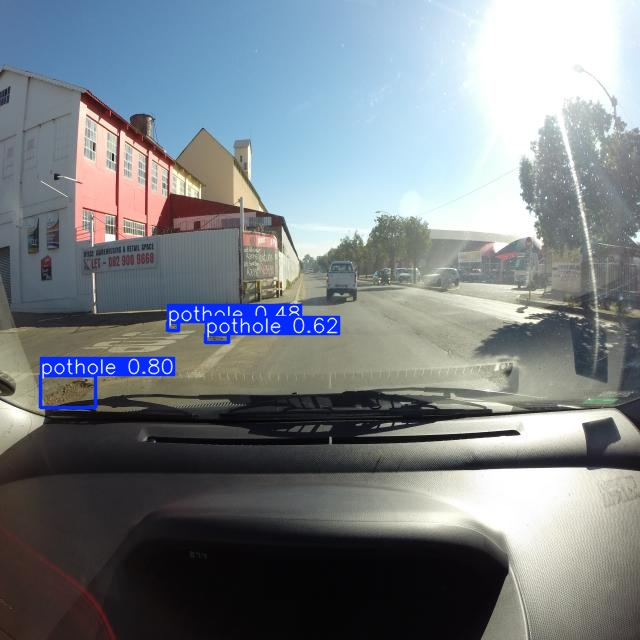

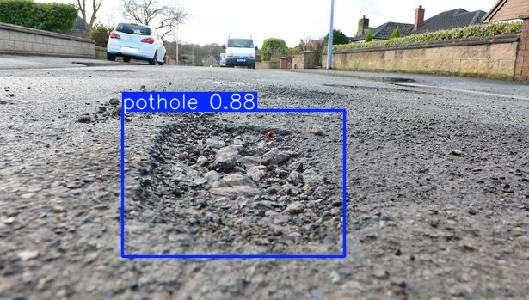

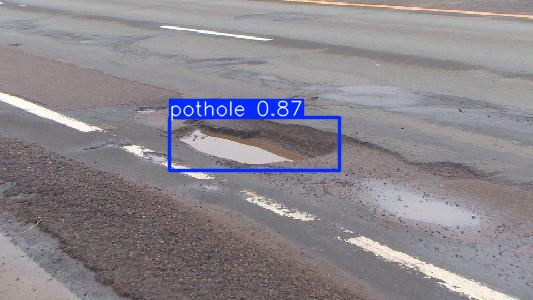

In [13]:
# Visual check on a few test images
imgs = glob.glob(f'{root}/{split}/images/*')[:6]
model.predict(imgs, imgsz=IMGSZ, conf=0.4, save=True, project='/content/preds', name='check', exist_ok=True)
for p in glob.glob('/content/preds/check/*')[:6]:
    display(Image(p, width=600))

## 8. Download weights

In [14]:
from google.colab import files
files.download(best)
print('Put this file in your project at: models/finetuned/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Put this file in your project at: models/finetuned/best.pt


Saving aug0_roboflow_pa071_jpg.rf.cb0fc507cc25234dbae555f0b6566dc5.jpg to aug0_roboflow_pa071_jpg.rf.cb0fc507cc25234dbae555f0b6566dc5.jpg

image 1/1 /content/aug0_roboflow_pa071_jpg.rf.cb0fc507cc25234dbae555f0b6566dc5.jpg: 960x960 1 pothole, 1 crack, 29.8ms
Speed: 3.6ms preprocess, 29.8ms inference, 1.4ms postprocess per image at shape (1, 3, 960, 960)
Results saved to /content/my_preds/out
pothole 0.86
crack 0.85


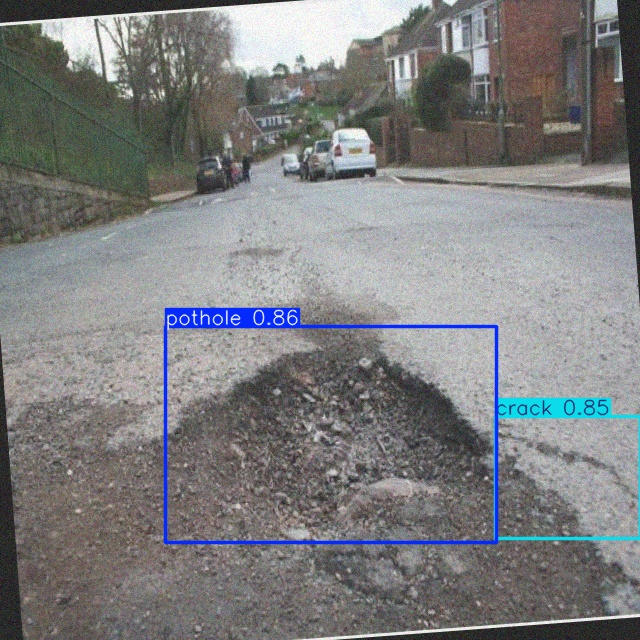

In [15]:
from google.colab import files
from ultralytics import YOLO
from IPython.display import Image, display
import glob, os

model = YOLO(f'{DRIVE_DIR}/runs/full/weights/best.pt')
uploaded = files.upload()

for name in uploaded:
    ext = name.lower().split('.')[-1]
    results = model.predict(name, imgsz=IMGSZ, conf=0.4, save=True,
                            project='/content/my_preds', name='out', exist_ok=True)

    if ext in ['jpg', 'jpeg', 'png', 'bmp', 'webp', 'tif']:
        for b in results[0].boxes:
            print(model.names[int(b.cls)], f"{float(b.conf):.2f}")
        display(Image(f'/content/my_preds/out/{name}', width=700))
    else:
        out = glob.glob('/content/my_preds/out/*')
        print('Video processed. Output files:', out)
        print('Left sidebar → Files → my_preds/out se download karo')